<a href="https://colab.research.google.com/github/sen-soumya/Optical-communication/blob/main/Adaptive_Optical_Link_for_energy_optimization_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1. Optical Link Environment Simulation

In [4]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import random
import matplotlib.pyplot as plt
from collections import deque

class OpticalLinkEnv:
    def __init__(self):
        self.state_dim = 3
        self.reset()

    def reset(self):
        self.history = [0.0, 0.0]
        self.temperature = 300.0
        return np.array([self.history[0], self.history[1], self.temperature], dtype=np.float32)

    def step(self, action, target_bit, lambda_energy):
        base_voltage = 1.5 if target_bit == 1 else 0.1
        input_voltage = np.clip(base_voltage + action, 0.0, 2.5)

        received_power = 0.7 * input_voltage + 0.15 * self.history[0] - 0.02 * (self.temperature - 300.0)
        received_power = np.tanh(received_power)

        self.history.insert(0, received_power)
        self.history.pop()
        self.temperature += 0.5 * (input_voltage ** 2) - 0.1 * (self.temperature - 300.0)

        target_power = 0.8 if target_bit == 1 else 0.05
        signal_error = (received_power - target_power) ** 2
        energy_penalty = lambda_energy * (input_voltage ** 2)

        reward = -(signal_error + energy_penalty)
        next_state = np.array([self.history[0], self.history[1], self.temperature], dtype=np.float32)
        return next_state, reward

# 2. DQN Agent

In [5]:
class QNetwork(nn.Module):
    def __init__(self, state_dim, action_dim_discrete):
        super().__init__()
        self.fc = nn.Sequential(
            nn.Linear(state_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, action_dim_discrete)
        )
    def forward(self, x):
        return self.fc(x)

class DQNAgent:
    def __init__(self, state_dim, lr=0.001):
        self.action_space = np.linspace(-0.5, 0.5, 11)
        self.memory = deque(maxlen=2000)
        self.gamma = 0.95
        self.epsilon = 1.0
        self.epsilon_decay = 0.99
        self.epsilon_min = 0.01

        self.model = QNetwork(state_dim, len(self.action_space))
        self.optimizer = optim.Adam(self.model.parameters(), lr=lr)

    def select_action(self, state):
        if random.random() < self.epsilon:
            return random.randint(0, len(self.action_space) - 1)
        state_t = torch.FloatTensor(state).unsqueeze(0)
        with torch.no_grad():
            return torch.argmax(self.model(state_t)).item()

    def train(self, batch_size=32):
        if len(self.memory) < batch_size:
            return
        batch = random.sample(self.memory, batch_size)
        states, actions, rewards, next_states = zip(*batch)

        states = torch.FloatTensor(np.array(states))
        actions = torch.LongTensor(actions).unsqueeze(1)
        rewards = torch.FloatTensor(rewards)
        next_states = torch.FloatTensor(np.array(next_states))

        current_q = self.model(states).gather(1, actions).squeeze()
        next_q = self.model(next_states).max(1)[0].detach()
        target_q = rewards + self.gamma * next_q

        loss = nn.MSELoss()(current_q, target_q)
        self.optimizer.zero_grad()
        loss.backward()
        self.optimizer.step()

        if self.epsilon > self.epsilon_min:
            self.epsilon *= self.epsilon_decay

# 3. Multiple Training Experiments

In [6]:
def run_experiment(lambda_energy, total_bits=600):
    env = OpticalLinkEnv()
    agent = DQNAgent(env.state_dim, lr=0.002)
    bit_stream = [random.choice([0, 1]) for _ in range(total_bits)]

    state = env.reset()
    reward_history = []
    moving_avg_rewards = []

    for idx, target_bit in enumerate(bit_stream):
        action_idx = agent.select_action(state)
        action_val = agent.action_space[action_idx]

        next_state, reward = env.step(action_val, target_bit, lambda_energy)
        agent.memory.append((state, action_idx, reward, next_state))

        agent.train()
        state = next_state
        reward_history.append(reward)

        if len(reward_history) >= 20:
            moving_avg_rewards.append(np.mean(reward_history[-20:]))
        else:
            moving_avg_rewards.append(np.mean(reward_history))

    return moving_avg_rewards, agent.model

experiments = {
    "Low Energy": 0.05,
    "Balanced": 0.30,
    "Strict Energy": 0.90
}

results = {}
trained_models = {}

for name, penalty in experiments.items():
    moving_rewards, trained_model = run_experiment(lambda_energy=penalty, total_bits=800)
    results[name] = moving_rewards
    trained_models[name] = trained_model
    torch.save(trained_model.state_dict(), f"dqn_laser_{penalty}.pth")

# 4. Performance Comparison Visualization

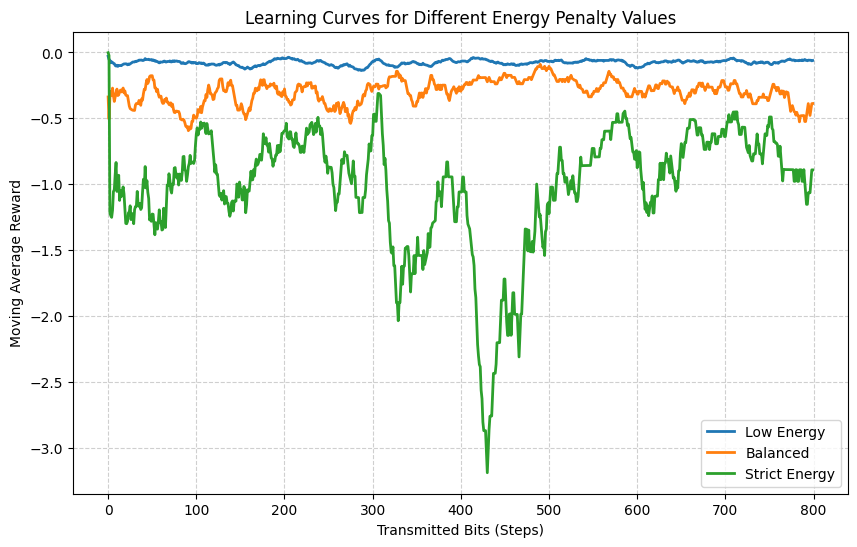

In [7]:
plt.figure(figsize=(10, 6))
for name, reward_curve in results.items():
    plt.plot(reward_curve, label=name, lw=2)

plt.title("Learning Curves for Different Energy Penalty Values")
plt.xlabel("Transmitted Bits (Steps)")
plt.ylabel("Moving Average Reward")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(loc="lower right")
plt.show()